# **Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
!pip install optuna
import optuna
from sklearn.linear_model import PoissonRegressor, GammaRegressor
from sklearn.metrics import mean_tweedie_deviance
from sklearn.model_selection import train_test_split
import warnings
!pip install pyreadr
import urllib.request
import pyreadr
warnings.filterwarnings('ignore')

# **Load Data**

In [ ]:
url = "https://github.com/dutangc/CASdatasets/raw/master/data/freMPL5.rda"
urllib.request.urlretrieve(url, "freMPL5.rda")

result = pyreadr.read_r("freMPL5.rda")
df_name = list(result.keys())[0]
df = result[df_name]

In [ ]:
df.columns

Index(['Exposure', 'LicAge', 'RecordBeg', 'RecordEnd', 'Gender', 'MariStat',
       'SocioCateg', 'VehUsage', 'DrivAge', 'HasKmLimit', 'ClaimAmount',
       'ClaimNbResp', 'ClaimNbNonResp', 'ClaimNbParking', 'ClaimNbFireTheft',
       'ClaimNbWindscreen', 'OutUseNb', 'RiskArea', 'BonusMalus', 'ClaimInd'],
      dtype='object')

In [ ]:
df.dtypes

,0
Exposure,float64
LicAge,int32
RecordBeg,object
RecordEnd,object
Gender,object
MariStat,object
SocioCateg,object
VehUsage,object
DrivAge,int32
HasKmLimit,int32


In [ ]:
df.describe()

,Exposure,LicAge,DrivAge,HasKmLimit,ClaimAmount,ClaimNbResp,ClaimNbNonResp,ClaimNbParking,ClaimNbFireTheft,ClaimNbWindscreen,OutUseNb,RiskArea,BonusMalus,ClaimInd
count,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.00000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000
mean,0.424910,355.583062,50.964250,0.074625,202.341405,0.26500,0.316312,0.084750,0.075063,0.419875,0.222000,7.835750,57.213875,0.092625
std,0.284496,156.024266,14.413477,0.262794,1645.340104,0.53037,0.605625,0.311366,0.287547,0.695241,0.652873,2.202544,14.042407,0.289915
min,0.001000,24.000000,20.000000,0.000000,-1842.013595,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,50.000000,0.000000
25%,0.173000,238.000000,40.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,50.000000,0.000000
50%,0.408000,361.500000,52.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,7.000000,50.000000,0.000000
75%,0.666000,467.000000,61.000000,0.000000,0.000000,0.00000,1.000000,0.000000,0.000000,1.000000,0.000000,10.000000,58.000000,0.000000
max,1.000000,844.000000,95.000000,1.000000,95150.962840,4.00000,7.000000,4.000000,3.000000,8.000000,5.000000,13.000000,185.000000,1.000000


In [ ]:
df.duplicated().sum()

np.int64(0)

# **Claim Number**

In [ ]:
df['ClaimNb'] = 0
for col in ['ClaimNbResp', 'ClaimNbNonResp', 'ClaimNbParking', 'ClaimNbFireTheft',
       'ClaimNbWindscreen']:
  df['ClaimNb'] += df[col]

# **Frequency, Severity and Loss Cost**

In [ ]:
df['frequency'] = df['ClaimNb'] / df['Exposure']
df['loss_cost'] = df['ClaimAmount'] / df['Exposure']
df['severity'] = np.where(df['ClaimNb']>0, df['ClaimAmount']/df['ClaimNb'], np.nan)

# **EDA**

**Claim Number Distribution**

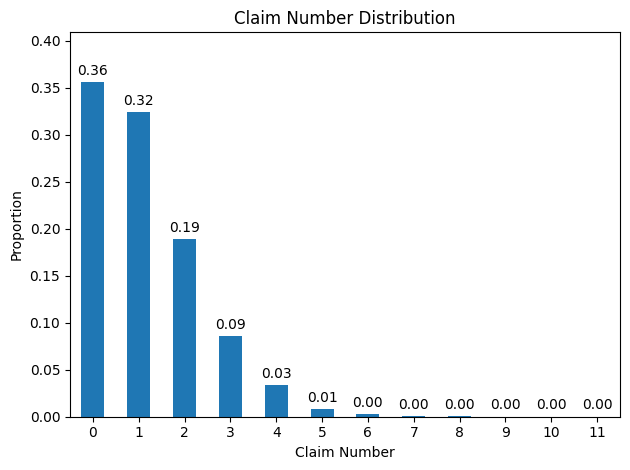

In [ ]:
claim = df.groupby('ClaimNb').size()/len(df)
claim = claim.sort_values(ascending=False)
ax = claim.plot(kind="bar")

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)

plt.title(f"Claim Number Distribution")
plt.ylabel("Proportion")
plt.xlabel("Claim Number")
rot = 0
plt.xticks(rotation=0, ha="right" if rot > 0 else "center")
plt.ylim(0, claim.max() * 1.15)
plt.tight_layout()
plt.show()

* 36% of policies have zero claims.
* 32% of policies have 1 claim.
* 99% of policies have claims less than 5.

**Severity Distribution**

In [ ]:
def plot_hist(data, col, log=False):
  sub = data[col]
  if col == 'severity':
    sub = data[(data['ClaimNb']>0)&(df['severity']>0)][col]

  if log:
      sub = np.log1p(sub)

  plt.hist(sub, bins=100, alpha=0.5, density=True)

  plt.xlabel(col if not log else 'log(1 + ' + col + ')')
  plt.ylabel("Density")
  plt.tight_layout()
  plt.show()

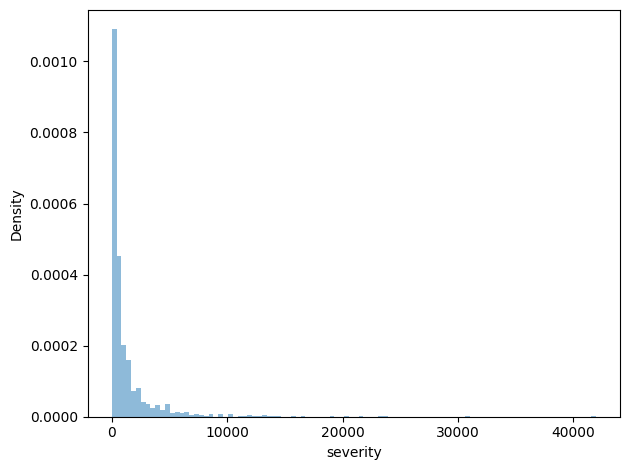

In [ ]:
plot_hist(df, 'severity')

* Severity is highly right skewed. We will apply log transformation.

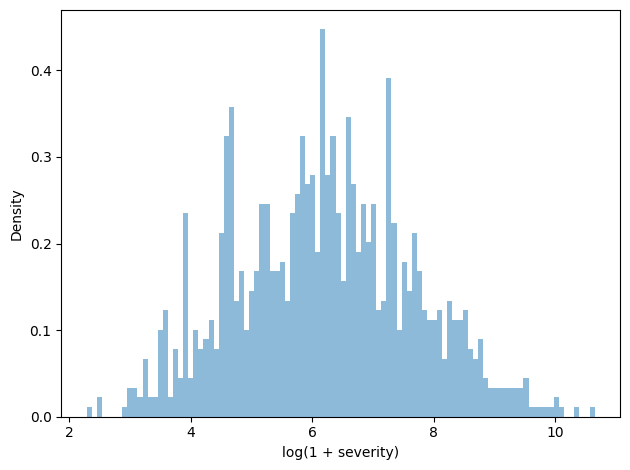

In [ ]:
plot_hist(df, 'severity', log=True)

* Log of severity is approximately bell shaped.
* We will use a baseline Gamma regressor to model severity.

**Loss Cost Distribution**

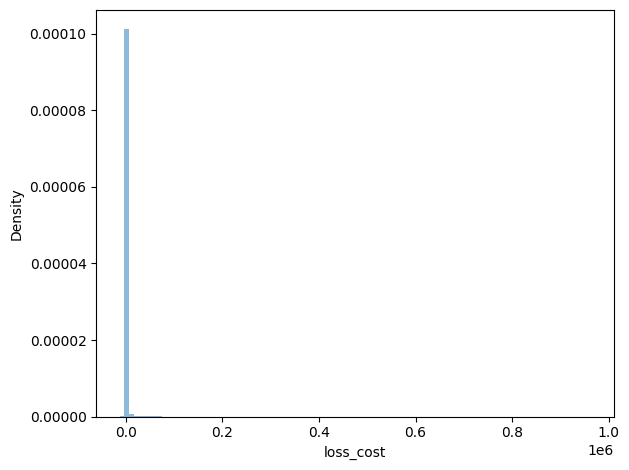

In [ ]:
plot_hist(df, 'loss_cost')

* Loss Cost has a tweedie shape, huge spike at zero and continous positive tail.
* We will use a tweedie objective to train LGBM.

**Frequency vs Driver Age**

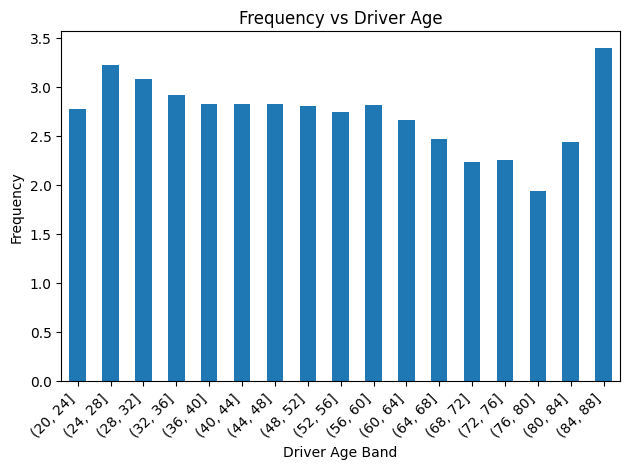

In [ ]:
df['age_band'] = pd.cut(df['DrivAge'], bins = range(20, 90, 4))
freq = df.groupby('age_band').apply(
    lambda x: x['ClaimNb'].sum() / x['Exposure'].sum()
)
freq.plot(kind = 'bar')
plt.title(f"Frequency vs Driver Age")
plt.ylabel("Frequency")
plt.xlabel("Driver Age Band")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Frequency vs Bonus Malus**

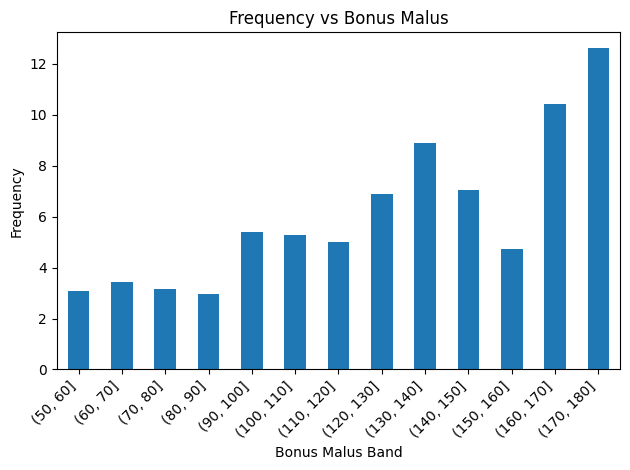

In [ ]:
df['bm_band'] = pd.cut(df['BonusMalus'], bins = range(50, 185, 10))
freq = df.groupby('bm_band').apply(
    lambda x: x['ClaimNb'].sum() / x['Exposure'].sum()
)
freq.plot(kind = 'bar')
plt.title(f"Frequency vs Bonus Malus")
plt.ylabel("Frequency")
plt.xlabel("Bonus Malus Band")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

* Frequency spikes at young and senior (older than 80) drivers.
* High BonusMalus (penalized) drivers carry elevated risk.

# **Feature Engineering**

We will add the following freatures:

* **Bonus Malus**:
    * `bm_centered`: Drivers start with a score of 100.
    * `bm_bonus`: Good drivers have a Bonus Malus score less than 100.
    * `bm_penality`
    * `bm_is_bonus`
    * `bm_is_penality`

* **Driver Age**:
    * `driv_age_sq` and `inv_driv_age`: Captures U-shape (young and senior) high risk
    * `young`
    * `senior`
* **License Age**:
    * `licage_years`: License Age in years
    * `first_year` and `first_two_years`: High risk drivers in their first two years
    * `licage_log`: Experience caries more risk signal at the lower end.

* **Experience Gap**: Identifies late starters, new arrivals
    * `experience_gap` and `late_starter`
    
* **Interaction**:
    * `young_x_risk_area` and `young_x_licAge_fst_2`: Young drivers at high risk areas and in thier first two years carry elevated risk.
    * `bm_penality_x_risk_area`: Penalized drivers in high risk areas also carry risk signal.
    * `bm_x_age`: Helps distinguish between a driver with BonusMalus of 60 at age 25 vs 60.
* **Ratios**:
    * `bm_to_licage`and `bm_to_age': Gives a BonusMalus score a license age and driver age context.
    

In [ ]:
# add bonus malus feature
def bonus_malus_features(df):
  df['bm_centered'] = df['BonusMalus'] - 100
  df['bm_bonus'] = np.maximum(0, 100 - df['BonusMalus'])
  df['bm_penality'] = np.maximum(0, df['BonusMalus'] - 100)
  df['bm_is_bonus'] = np.where(df['BonusMalus'] > 100, 1, 0)
  df['bm_is_penality'] = np.where(df['BonusMalus'] < 100, 1, 0)
  return df

# add driver age features
def age_features(df):
  df['driv_age_sq'] = df['DrivAge'] ** 2
  df['inv_driv_age'] = 1 / df['DrivAge']
  df['young'] = (df['DrivAge'] < 25).astype(int)
  df['senior'] = (df['DrivAge'] > 65).astype(int)
  return df

# add license age features
def license_features(df):
  df['licage_years'] = df['LicAge']/12
  df['first_year'] = (df['licage_years'] <= 1).astype(int)
  df['first_two_years'] = np.maximum(0, 2 - df['licage_years'])
  df['licage_log'] = np.log1p(df['licage_years'])
  return df

# add experience feature
def experience_feature(df):
  df['experience_gap'] = df['DrivAge'] - (18 + df['licage_years'])
  df['late_starter'] = (df['experience_gap'] > 5).astype(int)
  return df

In [ ]:
# add interaction features
def interaction_features(df):
  df['young_x_risk_area'] = df['young'] * df['RiskArea']
  df['young_x_licAge_fst_2'] = df['young'] * df['first_two_years']
  df['bm_penality_x_risk_area'] = df['bm_penality'] * df['RiskArea']
  df['bm_x_age'] = df['bm_centered'] * df['DrivAge']
  return df

def ratio_features(df):
  df['bm_to_licage'] = df['bm_centered'] / df['licage_years']
  df['bm_to_age'] = df['bm_centered'] / df['DrivAge']
  return df

In [ ]:
df = bonus_malus_features(df)
df = age_features(df)
df = license_features(df)
df = experience_feature(df)
df = interaction_features(df)
df = ratio_features(df)

**one hot encode Vehicle Usage for the GLMs**

In [ ]:
df['VehUsage_lgb'] = df['VehUsage']
df = pd.get_dummies(df, columns=['VehUsage'], drop_first=True)

In [ ]:
df.columns

Index(['Exposure', 'LicAge', 'RecordBeg', 'RecordEnd', 'Gender', 'MariStat',
       'SocioCateg', 'DrivAge', 'HasKmLimit', 'ClaimAmount', 'ClaimNbResp',
       'ClaimNbNonResp', 'ClaimNbParking', 'ClaimNbFireTheft',
       'ClaimNbWindscreen', 'OutUseNb', 'RiskArea', 'BonusMalus', 'ClaimInd',
       'ClaimNb', 'frequency', 'loss_cost', 'severity', 'bm_centered',
       'bm_bonus', 'bm_penality', 'bm_is_bonus', 'bm_is_penality',
       'driv_age_sq', 'inv_driv_age', 'young', 'senior', 'licage_years',
       'first_year', 'first_two_years', 'licage_log', 'experience_gap',
       'late_starter', 'young_x_risk_area', 'young_x_licAge_fst_2',
       'bm_penality_x_risk_area', 'bm_x_age', 'bm_to_licage', 'bm_to_age',
       'VehUsage_lgb', 'VehUsage_Private+trip to office',
       'VehUsage_Professional', 'VehUsage_Professional run'],
      dtype='object')

In [ ]:
num_cols = [
    'RiskArea', 'bm_centered',
    'bm_bonus', 'bm_penality', 'bm_is_bonus', 'bm_is_penality',
    'driv_age_sq', 'inv_driv_age', 'young', 'senior', 'licage_years',
    'first_year', 'first_two_years', 'licage_log', 'experience_gap',
    'late_starter', 'young_x_risk_area', 'young_x_licAge_fst_2',
    'bm_penality_x_risk_area', 'bm_x_age', 'bm_to_licage', 'bm_to_age'
]

cat_cols = ['VehUsage_lgb']
one_hot_cols = ['VehUsage_Private+trip to office',
       'VehUsage_Professional', 'VehUsage_Professional run']


comb_lgb = num_cols + cat_cols
comb_glm = num_cols + one_hot_cols

In [ ]:
df[comb_glm].isna().sum()

,0
RiskArea,0
bm_centered,0
bm_bonus,0
bm_penality,0
bm_is_bonus,0
bm_is_penality,0
driv_age_sq,0
inv_driv_age,0
young,0
senior,0


# **Train/Val/Test split**

We will split the dataset with the following percentages:

*   60% for training
*   20% for validation and
*   20% for test.



In [ ]:
tr, val_test = train_test_split(df, test_size = 0.4, random_state=42)
val, test = train_test_split(val_test, test_size = 0.2, random_state=42)

# **GLM Training**

* We will fit:
  * a **Poisson regression**
  * a **Gamma regression** to model frequency and severity respectively.
  
* We then compute **`PurePremium`** as the product of frequency and severity.

* We will use optuna to tune the alpha, L2 regularization parameter, with the objective of maximizing mean tweeide deviance.

In [ ]:
x_tr = tr[comb_glm]
x_va = val[comb_glm]
x_t = test[comb_glm]

## **Possion Regression**

In [ ]:
# we will fit the gamma regressor on training samples with non-zero claim numbers and severity
tr_g = tr[(tr['ClaimNb'] > 0) & (tr['severity'] > 0)]
x_tr_g = tr_g[comb_glm]

def objective(trial):

  possion_model = PoissonRegressor(
      alpha = trial.suggest_float('alpha_1', 1e-6, 10, log = True),
      max_iter = 1000
  )

  possion_model.fit(
      x_tr,
      tr['frequency'],
      sample_weight = tr['Exposure']
  )

  pred_f = possion_model.predict(x_va)


  gamma_model = GammaRegressor(
      alpha = trial.suggest_float('alpha_2', 1e-6, 10, log = True),
      max_iter = 1000
  )

  gamma_model.fit(
      x_tr_g,
      tr_g['severity'],
      sample_weight = tr_g['ClaimNb']
  )

  pred_s = gamma_model.predict(x_va)

  pred_loss_cost = pred_f * pred_s

  y_pred_clipped = np.clip(pred_loss_cost, 1e-6, None)
  y_true_clipped = np.clip(val['loss_cost'], 0, None)

  return mean_tweedie_deviance(y_true = y_true_clipped,
                               y_pred = y_pred_clipped,
                               sample_weight = val['Exposure'],
                               power = 1.5)

study = optuna.create_study(
    direction='minimize',
    sampler = optuna.samplers.TPESampler(),
    pruner = optuna.pruners.MedianPruner()
)

study.optimize(objective,
              n_trials = 25,
              show_progress_bar = True)

poisson_model = PoissonRegressor(
    alpha = study.best_params['alpha_1'],
    max_iter = 1000
)
poisson_model.fit(
    x_tr,
    tr['frequency'],
    sample_weight = tr['Exposure']
)

gamma_model = GammaRegressor(
    alpha = study.best_params['alpha_2'],
    max_iter = 1000
)

gamma_model.fit(
    x_tr_g,
    tr_g['severity'],
    sample_weight = tr_g['ClaimNb']
)

y_pred_val_freq =  poisson_model.predict(x_va)
y_pred_t_freq = poisson_model.predict(x_t)

y_pred_val_sev = gamma_model.predict(x_va)
y_pred_t_sev = gamma_model.predict(x_t)

y_pred_val_loss_cost = y_pred_val_freq * y_pred_val_sev

[I 2026-10-29 20:48:02,476] A new study created in memory with name: no-name-5aa17238-dfce-43ae-a25b-339ccd3de90e


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-10-29 20:48:02,539] Trial 0 finished with value: 217.99617680462322 and parameters: {'alpha_1': 5.049970156315316e-05, 'alpha_2': 1.065580201473185e-05}. Best is trial 0 with value: 217.99617680462322.
[I 2026-10-29 20:48:02,559] Trial 1 finished with value: 217.99617680462322 and parameters: {'alpha_1': 9.887659437167488e-06, 'alpha_2': 1.7226716259849972e-06}. Best is trial 0 with value: 217.99617680462322.
[I 2026-10-29 20:48:02,581] Trial 2 finished with value: 217.99617680462322 and parameters: {'alpha_1': 0.006715761814883392, 'alpha_2': 1.638186719284807}. Best is trial 0 with value: 217.99617680462322.
[I 2026-10-29 20:48:02,605] Trial 3 finished with value: 217.99617680462322 and parameters: {'alpha_1': 0.0008516682249201811, 'alpha_2': 5.012300236719133}. Best is trial 0 with value: 217.99617680462322.
[I 2026-10-29 20:48:02,625] Trial 4 finished with value: 217.99617680462322 and parameters: {'alpha_1': 0.00025260017205063135, 'alpha_2': 0.0002906403846964766}. Best 

# **LGBM**

* We will use Optuna to tune the following hyper-parameters with the objective of maximizing a custom mean_tweedie_deviance metric:

  * Learning rate
  * Number of leaves
  * Minimum data in leaf
  * Lambda l2 regularization
  * number of estimators

In [ ]:
x_tr = tr[comb_lgb]
x_va = val[comb_lgb]
x_test = test[comb_lgb]

In [ ]:
# 1. Cast categorical columns to pandas 'category' dtype so LightGBM can process them
x_tr = x_tr.copy()
x_va = x_va.copy()
x_test = x_test.copy()

for col in cat_cols:
    x_tr[col] = x_tr[col].astype('category')
    x_va[col] = x_va[col].astype('category')
    x_test[col] = x_test[col].astype('category')

y_tr_clipped = np.clip(tr['loss_cost'], 0, None)
y_val_clipped = np.clip(val['loss_cost'], 0, None)

tr_ds = lgb.Dataset(
        x_tr,
        label = y_tr_clipped,
        weight = tr['Exposure'],
        categorical_feature = cat_cols
    )

va_ds = lgb.Dataset(
        x_va,
        label = y_val_clipped,
        weight = val['Exposure'],
        categorical_feature = cat_cols
)


def mean_tweedie_deviance_feval(preds, dataset):
    labels = dataset.get_label()
    weight = dataset.get_weight()
    metric = mean_tweedie_deviance(y_true = labels,
                                  y_pred = np.clip(preds, 1e-6, None),
                                  sample_weight = weight,
                                  power = 1.5)
    return 'mwd', metric, False


def objective(trial):

    num_boost_round = trial.suggest_int('num_boost_round', 500, 1000)
    params = {
        'objective': 'tweedie',
        'metric': 'None',
        'verbose': -1,
        'feature_pre_filter': False,
        'tweedie_variance_power': trial.suggest_float('tweedie_variance_power', 1.0, 2.0),
        'learning_rate': trial.suggest_float('learning_rate', 1e-4, 1e-1, log = True),
        'num_leaves': trial.suggest_int('num_leaves', 31, 256, log = True),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 20, 1000, log = True),
        'lambda_l2': trial.suggest_float('lambda_l2', 1e-8, 10, log = True)
    }

    model = lgb.train(
        params,
        tr_ds,
        num_boost_round = num_boost_round,
        valid_sets = [va_ds],
        valid_names = ['val'],
        feval = mean_tweedie_deviance_feval,
        callbacks = [lgb.early_stopping(100)]
    )

    pred = model.predict(x_va)

    return mean_tweedie_deviance(y_true = y_val_clipped,
                                 y_pred = np.clip(pred, 1e-6, None),
                                 sample_weight = val['Exposure'],
                                 power = 1.5)

study = optuna.create_study(
    direction='minimize',
    sampler = optuna.samplers.TPESampler(),
    pruner = optuna.pruners.MedianPruner()
)

study.optimize(objective,
              n_trials = 25,
              show_progress_bar = True)

best_params = study.best_params.copy()
num_boost_round = best_params.pop('num_boost_round')

params = {
    'objective': 'tweedie',
    'metric': 'None',
    'verbose': -1,
    'feature_pre_filter': False,
    **best_params
}

model = lgb.train(
    params,
    tr_ds,
    num_boost_round = num_boost_round,
    valid_sets = [va_ds],
    valid_names = ['val'],
    feval = mean_tweedie_deviance_feval,
    callbacks = [lgb.early_stopping(100), lgb.log_evaluation(100)]
)

[I 2026-10-29 20:50:25,556] A new study created in memory with name: no-name-d807669c-b910-42a2-b4dd-efc724685db2


  0%|          | 0/25 [00:00<?, ?it/s]

Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[414]	val's mwd: 129.087
[I 2026-10-29 20:50:28,622] Trial 0 finished with value: 129.08714300996886 and parameters: {'num_boost_round': 563, 'tweedie_variance_power': 1.2781195151454163, 'learning_rate': 0.00045370435069727025, 'num_leaves': 66, 'min_data_in_leaf': 69, 'lambda_l2': 0.00024711068303317026}. Best is trial 0 with value: 129.08714300996886.
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[523]	val's mwd: 129.226
[I 2026-10-29 20:50:31,541] Trial 1 finished with value: 129.22550620822454 and parameters: {'num_boost_round': 523, 'tweedie_variance_power': 1.287108348845893, 'learning_rate': 0.000354983573376506, 'num_leaves': 60, 'min_data_in_leaf': 109, 'lambda_l2': 0.0034726956573572654}. Best is trial 0 with value: 129.08714300996886.
Training until validation scores don't improve for 100 rounds
Early stopping, best

In [ ]:
y_pred_loss_cost_val = model.predict(x_va)
y_pred_loss_cost_test = model.predict(x_test)

# **Mean Tweedie Deviance Reduction of 59% Over the Poission-Gamma Model**

In [ ]:
lgbm_mean_tweedie_deviance = mean_tweedie_deviance(y_true = y_val_clipped,
                                                   y_pred = np.clip(y_pred_loss_cost_val, 1e-6, None),
                                                   sample_weight = val['Exposure'],
                                                   power = 1.5)
glm_mean_tweedie_deviance = mean_tweedie_deviance(y_true = y_val_clipped,
                                                  y_pred = np.clip(y_pred_val_loss_cost, 1e-6, None),
                                                  sample_weight = val['Exposure'],
                                                  power = 1.5)
print(f'LGBM Mean Tweedie Deviance: {lgbm_mean_tweedie_deviance}')
print(f'GLM Mean Tweedie Deviance: {glm_mean_tweedie_deviance}')
print(f'Mean Tweedie Deviance Reduction: {lgbm_mean_tweedie_deviance/glm_mean_tweedie_deviance*100: .2f}')

LGBM Mean Tweedie Deviance: 128.45508401377637
GLM Mean Tweedie Deviance: 217.99617680462322
Mean Tweedie Deviance Reduction:  58.93


In [ ]:
model.save_model('loss_cost_lgbm.txt')
model = lgb.Booster(model_file = 'loss_cost_lgbm.txt')